# Ad-hoc: всплеск CTR `top_search` на Android 20 июля

## ТЗ

- Заказчик: продакт рекламного блока.
- Проблема: 20 июля на Android CTR `top_search` резко выше обычного, причину не знаем.
- Дедлайн: 2 рабочих дня.
- Глубина: разбор. Цена ошибки средняя, решение можно откатить: формат выключается флагом. Прикидки мало, нужны проверка данных, интервал и распределение. Других источников у меня нет.
- Метрика: `CTR = клики / показы` в процентах. Клик считаем по `click_id`, показ по `impression_id`.

| № | Пункт | Ответ |
|---|---|---|
| 1 | Цель | Разобраться, почему вырос CTR, и решить: чинить логирование или менять формат |
| 2 | Гипотеза | Всплеск из-за ошибки логирования кликов на Android. Другой вариант: реальный рост интереса к `top_search` |
| 3 | Метрика | Дневной CTR, отклики на клик и отклики на показ |
| 4 | Период | 1-28 июля 2026. Фокус: 20 июля. Базу выберем после проверки состава продуктов |
| 5 | Сегменты | Платформа, продукт, день. Сегмент работодателя |
| 6 | Критерий успеха | CTR 20 июля выходит за верхнюю границу 95% интервала обычных дней. Эффект реальный, если рост держится 3 дня и больше и виден в откликах |
| 7 | Решение | Если ошибка трекинга, чиним логирование и пересчитываем. Если эффект реальный, думаем, менять ли формат на Android |


============================================================

ИТОГОВАЯ СПРАВКА

============================================================

**Решение.** Формат `top_search` на Android не меняем. Сначала проверим логирование кликов за 20 июля: слишком похоже на сбой, но по этим данным доказать нельзя.

**Контекст.** 20 июля CTR `top_search` на Android 9.40%, база 2.95%. 21 июля CTR вернулся к 1.75%. Всплеск был только 20 июля.

**Что сделали.** Проверили данные, выбрали базу после запуска `top_boost`, сравнили CTR по платформам и продуктам, посмотрели воронку, сегменты, день недели и распределение.

**Результат.** 20 июля выросли оба продукта и все сегменты Android. Кроме Android небольшой рост только у `top_search` на mobile web. Отклики на клик точечно ниже, но различие в пределах шума.

**Ограничения.** За 20 июля всего 4 отклика на продукт. Нет логов, нет часов, повторных пользователей почти нет. База 13 дней, у `top_boost` всего 5 дней до 20 июля. Сравнение наблюдательное, не эксперимент. Несколько сравнений без поправки.

**Рекомендованное действие.** Проверить логирование кликов на Android за 20 июля. После исправления пересчитать CTR. Если логи чистые, считать всплеск разовым и формат не менять.

============================================================


## Данные

In [1]:
from pathlib import Path
from typing import Iterable, Optional, Sequence, Tuple

import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA = Path("data")
con = duckdb.connect()


def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = (
                    df[col]
                    .astype("Int64")
                    .map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
                )
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк из {filename}")
    return df


def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()


impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
print(f"даты: {impressions['event_date'].min()} - {impressions['event_date'].max()}")

impressions                    80,000 строк из impressions.csv
clicks                          3,837 строк из clicks.csv
responses                         421 строк из responses.csv
даты: 2026-07-01 - 2026-07-28


## Что в данных


In [2]:
def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


tables = [
    ("impressions", impressions, "impression_id"),
    ("clicks", clicks, "click_id"),
    ("responses", responses, "response_id"),
]
rows = []
for name, df, key in tables:
    dq = summarize_dq(df, [key]).set_index("проверка")["значение"]
    rows.append({
        "таблица": name,
        "строк": dq["строк всего"],
        "полных дублей": dq["полных дублей строк"],
        "дублей по ключу": dq[f"дубли по ключу: {key}"],
        "пропусков": dq[dq.index.str.startswith("пропуски")].sum(),
    })
display(pd.DataFrame(rows))

,таблица,строк,полных дублей,дублей по ключу,пропусков
0,impressions,80000,0,0,0
1,clicks,3837,0,0,0
2,responses,421,0,0,0


In [3]:
checks = pd.Series({
    "клики без показа": (~clicks["impression_id"].isin(impressions["impression_id"])).sum(),
    "отклики без клика": (~responses["click_id"].isin(clicks["click_id"])).sum(),
    "отклики без показа": (~responses["impression_id"].isin(impressions["impression_id"])).sum(),
    "показов с несколькими кликами": (clicks.groupby("impression_id").size() > 1).sum(),
    "кликов с несколькими откликами": (responses.groupby("click_id").size() > 1).sum(),
})
display(checks.to_frame("значение"))

,значение
клики без показа,0
отклики без клика,0
отклики без показа,0
показов с несколькими кликами,0
кликов с несколькими откликами,0


- Полных дублей, дублей по ключам и пропусков нет ни в одной таблице.
- Клики и отклики ссылаются на существующие показы и клики. Повторных кликов на один показ и откликов на один клик нет.


## 20 июля

In [4]:
android_impressions = sql("""
    select * from impressions
    where platform = 'ANDROID' and event_date = '2026-07-20'
""")
android_clicks = sql("""
    select * from clicks
    where platform = 'ANDROID' and event_date = '2026-07-20'
""")

print(
    "20 июля: показов", len(android_impressions),
    "пользователей", android_impressions["hhuid"].nunique(),
)
imp_per_user = android_impressions["hhuid"].value_counts()
print("Показы на пользователя:")
print(imp_per_user.value_counts().sort_index().rename_axis("показов").to_frame("пользователей"))

click_per_user = android_clicks["hhuid"].value_counts()
print("Клики на пользователя:")
print(click_per_user.value_counts().sort_index().rename_axis("кликов").to_frame("пользователей"))

many_impressions = imp_per_user[imp_per_user > 1].index
print(
    "Клики пользователей с несколькими показами:",
    android_clicks[android_clicks["hhuid"].isin(many_impressions)].shape[0],
)
print("Дубли hhuid + vacancy_id в кликах:", android_clicks.duplicated(["hhuid", "vacancy_id"]).sum())
print("Кликов:", len(android_clicks), "пользователей:", android_clicks["hhuid"].nunique())

print("Клики по продуктам:")
print(android_clicks["product"].value_counts().rename_axis("продукт").to_frame("кликов"))

20 июля: показов 635 пользователей 634
Показы на пользователя:
         пользователей
показов               
1                  633
2                    1
Клики на пользователя:
        пользователей
кликов               
1                  65
Клики пользователей с несколькими показами: 0
Дубли hhuid + vacancy_id в кликах: 0
Кликов: 65 пользователей: 65
Клики по продуктам:
            кликов
продукт           
top_search      36
top_boost       29


- 20 июля на Android 635 показов на 634 пользователя. У 633 пользователей по одному показу, у одного два. Этот пользователь не кликал.
- 65 кликов от 65 пользователей: 36 в `top_search`, 29 в `top_boost`.
- Дублей `hhuid` + `vacancy_id` нет.


## Дневной CTR

Смотрю CTR по дням, платформам и продуктам. Сначала нужно понять, когда появился `top_boost` и как изменился поток показов `top_search` на Android, чтобы выбрать базу для 20 июля.


In [5]:
launch = sql("""
select product, min(event_date) as первый_день, max(event_date) as последний_день
from impressions
where year = '2026' and month = '07'
group by 1
order by 2
""")
display(launch)

android_top_search = impressions[
    (impressions["platform"] == "ANDROID") & (impressions["product"] == "top_search")
]
before = android_top_search[android_top_search["event_date"] < "2026-07-15"].groupby("event_date").size().mean()
after = android_top_search[android_top_search["event_date"] >= "2026-07-15"].groupby("event_date").size().mean()
print(f"Средние показы top_search на Android: до 15 июля {before:.0f}, с 15 июля {after:.0f}")

,product,первый_день,последний_день
0,top_search,2026-07-01,2026-07-28
1,top_boost,2026-07-15,2026-07-28


Средние показы top_search на Android: до 15 июля 636, с 15 июля 384


### База

`top_boost` появился 15 июля. После этого средние показы `top_search` на Android упали с 636 до 384 в день, так что сравнивать 20 июля со всем июлем было бы нечестно. Взял базу 15-19 и 21-28 июля.


In [6]:
daily = sql("""
with impr as (
    select event_date, platform, product, count(*) as impressions
    from impressions
    where year = '2026' and month = '07'
    group by 1, 2, 3
),
clk as (
    select event_date, platform, product, count(*) as clicks
    from clicks
    where year = '2026' and month = '07'
    group by 1, 2, 3
)
select
    i.event_date,
    i.platform,
    i.product,
    i.impressions,
    coalesce(c.clicks, 0) as clicks
from impr i
left join clk c using (event_date, platform, product)
order by 1, 2, 3
""")
print("строк:", len(daily))
display(daily.head(10))

строк: 168


,event_date,platform,product,impressions,clicks
0,2026-07-01,ANDROID,top_search,599,16
1,2026-07-01,DESKTOP_WEB,top_search,1045,74
2,2026-07-01,IOS,top_search,493,17
3,2026-07-01,MOBILE_WEB,top_search,634,30
4,2026-07-02,ANDROID,top_search,623,21
5,2026-07-02,DESKTOP_WEB,top_search,1094,63
6,2026-07-02,IOS,top_search,529,12
7,2026-07-02,MOBILE_WEB,top_search,608,28
8,2026-07-03,ANDROID,top_search,683,29
9,2026-07-03,DESKTOP_WEB,top_search,1092,62


In [7]:
def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


daily_ci = proportion_table(
    daily,
    group_cols=["event_date", "platform", "product"],
    success_col="clicks",
    n_col="impressions",
    rate_name="ctr",
)

view = daily_ci.head(10).rename(columns={
    "successes": "клики",
    "n": "показы",
    "ctr": "CTR",
    "ci_low": "CI низ",
    "ci_high": "CI верх",
})
for col in ["CTR", "CI низ", "CI верх"]:
    view[col] = view[col].map("{:.2%}".format)
display(view)

,event_date,platform,product,клики,показы,CTR,CI низ,CI верх
0,2026-07-01,ANDROID,top_search,16,599,2.67%,1.65%,4.29%
1,2026-07-01,DESKTOP_WEB,top_search,74,1045,7.08%,5.68%,8.80%
2,2026-07-01,IOS,top_search,17,493,3.45%,2.16%,5.45%
3,2026-07-01,MOBILE_WEB,top_search,30,634,4.73%,3.33%,6.67%
4,2026-07-02,ANDROID,top_search,21,623,3.37%,2.22%,5.10%
5,2026-07-02,DESKTOP_WEB,top_search,63,1094,5.76%,4.53%,7.30%
6,2026-07-02,IOS,top_search,12,529,2.27%,1.30%,3.92%
7,2026-07-02,MOBILE_WEB,top_search,28,608,4.61%,3.21%,6.58%
8,2026-07-03,ANDROID,top_search,29,683,4.25%,2.97%,6.03%
9,2026-07-03,DESKTOP_WEB,top_search,62,1092,5.68%,4.45%,7.21%


In [8]:
july20 = daily_ci[daily_ci["event_date"] == "2026-07-20"]
baseline = daily_ci[(daily_ci["event_date"] >= "2026-07-15") & (daily_ci["event_date"] != "2026-07-20")]

rows = []
for _, day in july20.iterrows():
    base = baseline[(baseline["platform"] == day["platform"]) & (baseline["product"] == day["product"])]
    p0 = base["successes"].sum() / base["n"].sum()
    lo0, hi0 = wilson_ci(base["successes"].sum(), base["n"].sum())
    rows.append({
        "платформа": day["platform"],
        "продукт": day["product"],
        "показы": int(day["n"]),
        "клики": int(day["successes"]),
        "CTR 20.07": f"{day['ctr']:.2%} ({day['ci_low']:.2%}-{day['ci_high']:.2%})",
        "база (95% интервал)": f"{p0:.2%} ({lo0:.2%}-{hi0:.2%})",
        "прирост, п.п.": (day["ctr"] - p0) * 100,
        "интервалы пересекаются?": "да" if (day["ci_low"] <= hi0 and lo0 <= day["ci_high"]) else "нет",
    })

compare = pd.DataFrame(rows).sort_values("прирост, п.п.", ascending=False)
compare["прирост, п.п."] = compare["прирост, п.п."].round(1)
display(compare.reset_index(drop=True))

,платформа,продукт,показы,клики,CTR 20.07,база (95% интервал),"прирост, п.п.",интервалы пересекаются?
0,ANDROID,top_boost,252,29,11.51% (8.13%-16.04%),4.43% (3.75%-5.21%),7.1,нет
1,ANDROID,top_search,383,36,9.40% (6.87%-12.74%),2.95% (2.51%-3.45%),6.5,нет
2,MOBILE_WEB,top_search,406,32,7.88% (5.64%-10.92%),4.89% (4.32%-5.52%),3.0,нет
3,DESKTOP_WEB,top_search,714,47,6.58% (4.99%-8.64%),5.42% (4.96%-5.92%),1.2,да
4,DESKTOP_WEB,top_boost,429,34,7.93% (5.73%-10.87%),7.19% (6.53%-7.91%),0.7,да
5,IOS,top_boost,186,8,4.30% (2.20%-8.26%),4.23% (3.52%-5.07%),0.1,да
6,IOS,top_search,293,9,3.07% (1.62%-5.73%),3.42% (2.91%-4.01%),-0.3,да
7,MOBILE_WEB,top_boost,246,14,5.69% (3.42%-9.32%),6.59% (5.77%-7.52%),-0.9,да


In [9]:
around = daily_ci.query(
    "platform == 'ANDROID' and '2026-07-18' <= event_date <= '2026-07-22'"
).copy()
around = around.rename(columns={"n": "показы", "successes": "клики"})
around["CTR"] = around.apply(
    lambda r: f"{r['ctr']:.2%} ({r['ci_low']:.2%}-{r['ci_high']:.2%})",
    axis=1,
)
display(around[["event_date", "product", "показы", "клики", "CTR"]].reset_index(drop=True))

,event_date,product,показы,клики,CTR
0,2026-07-18,top_boost,246,7,2.85% (1.39%-5.76%)
1,2026-07-18,top_search,371,11,2.96% (1.66%-5.23%)
2,2026-07-19,top_boost,226,12,5.31% (3.06%-9.05%)
3,2026-07-19,top_search,362,11,3.04% (1.71%-5.36%)
4,2026-07-20,top_boost,252,29,11.51% (8.13%-16.04%)
5,2026-07-20,top_search,383,36,9.40% (6.87%-12.74%)
6,2026-07-21,top_boost,211,8,3.79% (1.93%-7.30%)
7,2026-07-21,top_search,400,7,1.75% (0.85%-3.57%)
8,2026-07-22,top_boost,234,13,5.56% (3.28%-9.27%)
9,2026-07-22,top_search,362,15,4.14% (2.53%-6.72%)


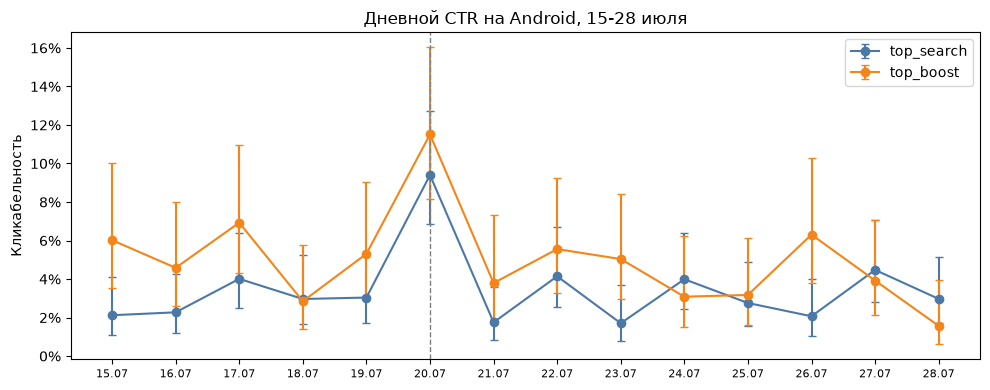

In [10]:
android = daily_ci.query("platform == 'ANDROID' and event_date >= '2026-07-15'").copy()
android["event_date"] = pd.to_datetime(android["event_date"])

fig, ax = plt.subplots(figsize=(10, 4))
for product, color in [("top_search", "#4C78A8"), ("top_boost", "#F58518")]:
    part = android[android["product"] == product]
    ax.errorbar(
        part["event_date"],
        part["ctr"],
        yerr=[part["ctr"] - part["ci_low"], part["ci_high"] - part["ctr"]],
        marker="o",
        capsize=3,
        label=product,
        color=color,
    )

ax.axvline(mdates.date2num(pd.Timestamp("2026-07-20")), color="gray", linestyle="--", linewidth=1)
ax.set_title("Дневной CTR на Android, 15-28 июля")
ax.set_ylabel("Кликабельность")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.tick_params(axis="x", labelsize=8)
ax.legend()
plt.tight_layout()
plt.show()

- 20 июля CTR `top_search` на Android 9.40% (95% интервал 6.87-12.74%), база 2.95% (2.51-3.45%). Интервалы не пересекаются.
- `top_boost` в тот же день 11.51% (8.13-16.04%) против 4.43% (3.75-5.21%). На Android выросли оба продукта.
- Кроме Android заметен `top_search` на mobile web: 7.9% против 4.9%. Но это верхняя граница его обычного диапазона 2.9-7.2%, а `top_boost` там не вырос. Поэтому главный сигнал все равно Android.
- 21 июля CTR вернулся к обычному: 1.75% у `top_search` и 3.79% у `top_boost`. Всплеск был только 20 июля.


## Воронка

Проверяю, выросли ли отклики вместе с кликами. Если клики задвоились или пришли от ботов, отклики на клик просядут, а отклики на показ останутся на месте.


In [11]:
responses_daily = sql("""
select event_date, platform, product, count(*) as responses
from responses
where year = '2026' and month = '07'
group by 1, 2, 3
""")

funnel = daily.merge(
    responses_daily,
    on=["event_date", "platform", "product"],
    how="left",
)
funnel["responses"] = funnel["responses"].fillna(0).astype(int)

rows = []
for product in ["top_search", "top_boost"]:
    day = funnel.query(
        "platform == 'ANDROID' and product == @product and event_date == '2026-07-20'"
    ).iloc[0]
    base = funnel.query(
        "platform == 'ANDROID' and product == @product"
        " and event_date >= '2026-07-15' and event_date != '2026-07-20'"
    )
    for metric, denominator in [("на клик", "clicks"), ("на показ", "impressions")]:
        k, n = int(day["responses"]), int(day[denominator])
        k0, n0 = int(base["responses"].sum()), int(base[denominator].sum())
        lo, hi = wilson_ci(k, n)
        lo0, hi0 = wilson_ci(k0, n0)
        rows.append({
            "продукт": product,
            "отклики": metric,
            "20 июля": f"{k}/{n} = {k/n:.1%} ({lo:.1%}-{hi:.1%})",
            "база": f"{k0}/{n0} = {k0/n0:.1%} ({lo0:.1%}-{hi0:.1%})",
            "интервалы пересекаются?": "да" if (lo <= hi0 and lo0 <= hi) else "нет",
        })

display(pd.DataFrame(rows))

,продукт,отклики,20 июля,база,интервалы пересекаются?
0,top_search,на клик,4/36 = 11.1% (4.4%-25.3%),22/147 = 15.0% (10.1%-21.6%),да
1,top_search,на показ,4/383 = 1.0% (0.4%-2.7%),22/4990 = 0.4% (0.3%-0.7%),да
2,top_boost,на клик,4/29 = 13.8% (5.5%-30.6%),28/136 = 20.6% (14.6%-28.1%),да
3,top_boost,на показ,4/252 = 1.6% (0.6%-4.0%),28/3073 = 0.9% (0.6%-1.3%),да


- 20 июля на Android по 4 отклика в каждом продукте. Отклики на клик ниже базы: 11.1% против 15.0% у `top_search` и 13.8% против 20.6% у `top_boost`.
- Отклики на показ выше: 1.0% против 0.4% и 1.6% против 0.9%.
- Во всех четырех сравнениях интервалы пересекаются. На 4 откликах воронка ничего не доказывает: падение качества кликов и реальный рост выглядят одинаково.

Хотел опереться на отклики, но 4 отклика на продукт для этого мало. Оставил воронку как проверку, а не как доказательство.


## Сегменты

Проверяю, не сидит ли всплеск в одном сегменте и не объясняется ли он сдвигом состава показов.


In [12]:
segment_daily = sql("""
select
    i.product,
    i.segment,
    i.event_date,
    count(*) as impressions,
    count(c.click_id) as clicks
from impressions i
left join clicks c using (impression_id)
where i.platform = 'ANDROID' and i.event_date >= '2026-07-15'
group by 1, 2, 3
""")

rows = []
for (product, segment), part in segment_daily.groupby(["product", "segment"]):
    day = part[part["event_date"] == "2026-07-20"]
    base = part[part["event_date"] != "2026-07-20"]
    imp_day, clk_day = int(day["impressions"].sum()), int(day["clicks"].sum())
    imp_base, clk_base = int(base["impressions"].sum()), int(base["clicks"].sum())
    rows.append({
        "продукт": product,
        "сегмент": segment,
        "показы 20.07": imp_day,
        "клики 20.07": clk_day,
        "CTR 20.07": f"{clk_day/imp_day:.1%}",
        "CTR база": f"{clk_base/imp_base:.1%}",
        "прирост, п.п.": round((clk_day/imp_day - clk_base/imp_base) * 100, 1),
    })

display(pd.DataFrame(rows))

,продукт,сегмент,показы 20.07,клики 20.07,CTR 20.07,CTR база,"прирост, п.п."
0,top_boost,Large,87,10,11.5%,4.4%,7.1
1,top_boost,Premium,31,2,6.5%,4.5%,2.0
2,top_boost,SMB,134,17,12.7%,4.4%,8.2
3,top_search,Large,111,12,10.8%,2.9%,7.9
4,top_search,Premium,62,4,6.5%,3.6%,2.8
5,top_search,SMB,210,20,9.5%,2.8%,6.7


- Судя по точкам, CTR вырос во всех шести сегментах: от 6.5% до 12.7% 20 июля против 2.8-4.5% в базе.
- Одним сегментом или сдвигом состава показов это не объяснить. Похоже, вырос весь Android.


## Пользователи и вакансии

Проверяю, не пришли ли клики от разовых пользователей или на узкий круг вакансий.


In [13]:
android_clicks_window = sql("""
select * from clicks
where platform = 'ANDROID' and event_date >= '2026-07-15'
""")

user_days = impressions.groupby("hhuid")["event_date"].nunique()
clickers = android_clicks_window.groupby(["event_date", "hhuid"], as_index=False).size()
clickers["only_day"] = clickers["hhuid"].map(user_days) == 1

day20 = clickers[clickers["event_date"] == "2026-07-20"]
other = clickers[clickers["event_date"] != "2026-07-20"]
other_share = other.groupby("event_date")["only_day"].mean()
print(
    "Встречаются в показах только в один день:",
    f"20 июля {int(day20['only_day'].sum())} из {len(day20)} ({day20['only_day'].mean():.0%}),",
    f"остальные дни {other_share.min():.0%}-{other_share.max():.0%}",
)

rows = []
for label, part in [
    ("20 июля", android_clicks_window[android_clicks_window["event_date"] == "2026-07-20"]),
    ("база", android_clicks_window[android_clicks_window["event_date"] != "2026-07-20"]),
]:
    for product in ["top_search", "top_boost"]:
        x = part[part["product"] == product]
        rows.append({
            "период": label,
            "продукт": product,
            "клики": len(x),
            "вакансий": x["vacancy_id"].nunique(),
            "работодателей": x["employer_id"].nunique(),
        })

display(pd.DataFrame(rows))


Встречаются в показах только в один день: 20 июля 56 из 65 (86%), остальные дни 80%-100%


,период,продукт,клики,вакансий,работодателей
0,20 июля,top_search,36,36,36
1,20 июля,top_boost,29,29,29
2,база,top_search,147,147,144
3,база,top_boost,136,136,132


- 20 июля 56 из 65 кликавших встречаются в показах только в один день за месяц. В остальные дни таких 80-100%, так что по этому признаку день не выделяется.
- Хотел проверить, не боты ли это, но повторных пользователей в данных почти нет. Зато 65 кликов пришли от 65 пользователей, 36 и 29 разных вакансий и работодателей. Всплеск размазан по пользователям и вакансиям, это не один бот и не одна вакансия.


## День недели

20 июля выпало на понедельник. Проверяю, нет ли у понедельников своего уровня CTR.


In [14]:
weekday = daily_ci.query(
    "platform == 'ANDROID' and product == 'top_search' and event_date >= '2026-07-15'"
).copy()
weekday["event_date"] = pd.to_datetime(weekday["event_date"])

monday_20 = weekday[weekday["event_date"] == "2026-07-20"].iloc[0]
monday_27 = weekday[weekday["event_date"] == "2026-07-27"].iloc[0]
rest = weekday[~weekday["event_date"].dt.day_name().eq("Monday")]

rows = [
    {
        "день": "20 июля, понедельник",
        "показы": int(monday_20["n"]),
        "клики": int(monday_20["successes"]),
        "CTR": f"{monday_20['ctr']:.1%}",
    },
    {
        "день": "27 июля, понедельник",
        "показы": int(monday_27["n"]),
        "клики": int(monday_27["successes"]),
        "CTR": f"{monday_27['ctr']:.1%}",
    },
    {
        "день": "остальные дни",
        "показы": int(rest["n"].sum()),
        "клики": int(rest["successes"].sum()),
        "CTR": f"{rest['successes'].sum() / rest['n'].sum():.1%}",
    },
]

display(pd.DataFrame(rows))

,день,показы,клики,CTR
0,"20 июля, понедельник",383,36,9.4%
1,"27 июля, понедельник",380,17,4.5%
2,остальные дни,4610,130,2.8%


- 20 июля 9.4%, второй понедельник 27 июля 4.5%, остальные дни 2.8%.
- День недели, скорее всего, ни при чем, но понедельников в данных всего два, так что проверка слабая.


## Распределение

Смотрю дневной CTR `top_search` по платформам за 15-28 июля. Нужно понять, насколько 20 июля выбивается из обычного разброса.


ANDROID: 20 июля 9.4%, остальные дни 1.7%-4.5%
MOBILE_WEB: 20 июля 7.9%, остальные дни 2.9%-7.2%
IOS: 20 июля 3.1%, остальные дни 2.2%-5.6%
DESKTOP_WEB: 20 июля 6.6%, остальные дни 4.7%-6.9%


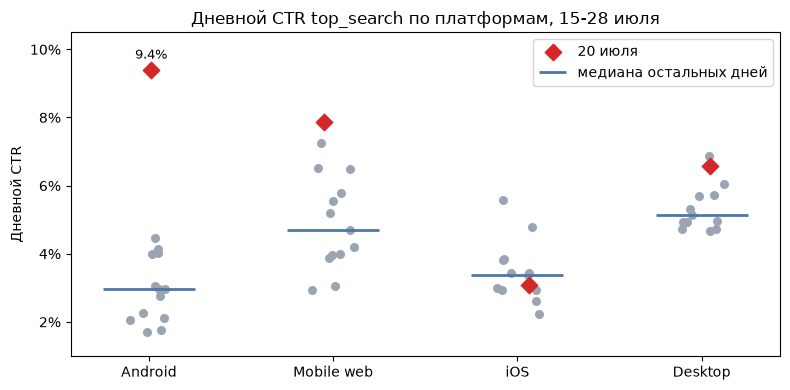

In [15]:
dist = daily_ci.query(
    "product == 'top_search' and event_date >= '2026-07-15'"
).copy()
dist["event_date"] = pd.to_datetime(dist["event_date"])
platforms = ["ANDROID", "MOBILE_WEB", "IOS", "DESKTOP_WEB"]

for platform in platforms:
    part = dist[dist["platform"] == platform]
    day = part.loc[part["event_date"] == "2026-07-20", "ctr"].iloc[0]
    rest = part.loc[part["event_date"] != "2026-07-20", "ctr"]
    print(f"{platform}: 20 июля {day:.1%}, остальные дни {rest.min():.1%}-{rest.max():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
rng = np.random.default_rng(14)

for i, platform in enumerate(platforms):
    part = dist[dist["platform"] == platform]
    jitter = rng.uniform(-0.12, 0.12, len(part))
    is_20 = (part["event_date"] == "2026-07-20").to_numpy()

    ax.scatter(i + jitter[~is_20], part["ctr"][~is_20], color="#9AA5B1", s=30, zorder=2)
    ax.scatter(
        i + jitter[is_20],
        part["ctr"][is_20],
        color="#D62728",
        s=70,
        marker="D",
        zorder=3,
        label="20 июля" if platform == "ANDROID" else None,
    )

    median = part.loc[part["event_date"] != "2026-07-20", "ctr"].median()
    ax.hlines(
        median,
        i - 0.25,
        i + 0.25,
        color="#4C78A8",
        linewidth=2,
        label="медиана остальных дней" if platform == "ANDROID" else None,
    )

    if platform == "ANDROID":
        ax.annotate(
            f"{part.loc[part['event_date'] == '2026-07-20', 'ctr'].iloc[0]:.1%}",
            (i + jitter[is_20][0], part.loc[part["event_date"] == "2026-07-20", "ctr"].iloc[0]),
            textcoords="offset points",
            xytext=(0, 8),
            ha="center",
            fontsize=9,
        )

ax.set_xticks(range(len(platforms)))
ax.set_xticklabels(["Android", "Mobile web", "iOS", "Desktop"])
ax.set_ylim(0.01, 0.105)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.set_ylabel("Дневной CTR")
ax.set_title("Дневной CTR top_search по платформам, 15-28 июля")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

- Android 20 июля 9.4% при обычных 1.7-4.5%. Это выше всех остальных дней Android за 15-28 июля.
- Mobile web 7.9% при 2.9-7.2%, чуть выше верхней границы. Desktop и iOS в обычном диапазоне.
- Судя по данным, причина в платформе, а не в формате `top_search`: на desktop и iOS тот же продукт не вырос. Небольшой рост на mobile web ниже и не подкреплен `top_boost`, так что это скорее край диапазона, чем второй сигнал.


## Почему такой вывод

20 июля выросли оба продукта, а 21 июля все вернулось к обычному уровню. Рост виден во всех сегментах Android. Отклики за кликами не выросли: 11.1% против 15.0% у `top_search` и 13.8% против 20.6% у `top_boost`, интервалы пересекаются.

Похоже на сбой логирования, но доказать это по этим данным нельзя. Воронка на 4 откликах ничего не доказывает, логов и часов нет, повторных пользователей почти нет. Поэтому сначала проверяем логи, а формат не трогаем.
